# 第 04 关：把公司特征变成因子收益

**本关要回答的问题：** 第 03 关发现 CAPM 解释不了规模和 B/M 带来的收益差异。Fama 和 French（1993）的办法是：把"规模"和"价值"也做成像市场一样的**月度收益序列**，作为新的解释变量放进回归。这些序列是怎样构造出来的？

### 为什么用"多空组合的收益"代表一个因子？
因子要代表许多股票共同面对的某种风险来源。"规模风险"无法直接观测，但我们可以构造一个对它有暴露、对其他东西尽量没有暴露的组合：**买入小公司股票，同时卖空同样金额的大公司股票**。这个组合每个月的收益，就记录了"小公司相对大公司"这个方向上发生了什么。这样得到的因子叫**模拟因子组合**（factor-mimicking portfolio）。

这样做有两个好处：一是每个月都能观测到，可以直接放进时间序列回归；二是它本身就是一个可以投资的组合收益，因此模型对它的定价有明确的含义（第 06 关会用到）。

### 两个因子
- **SMB（Small Minus Big）**：小市值组合的平均收益 − 大市值组合的平均收益。
- **HML（High Minus Low）**：高 B/M 组合的平均收益 − 低 B/M 组合的平均收益。

请分清三个对象：**特征**（公司的市值、B/M，用来决定分组）→ **因子收益**（分组形成组合之后实际实现的收益）→ **因子暴露**（某个资产的收益对因子收益的回归斜率）。

### 分组的时间顺序
每年 6 月底分组一次，然后持有 7 月到次年 6 月：
- 规模用当年 6 月底的市值；
- B/M 用上一财年的账面权益除以上一年 12 月底的市值。

会计数据至少滞后半年，是为了保证分组时这些财报已经公布。如果用了当时还没公布的信息，组合在现实中无法构造，这种错误叫**前视偏差**。

完整规则见[官方六组合说明](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library/six_portfolios.html)和[官方因子公式](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library/f-f_factors.html)。

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/course.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from course import (load_raw, load_returns, raw_path, catalog, manifest, style,
                    build_ff3, build_ff5, heatmap25, save_table, paper_note)
from analysis import fit_models, grs_test, model_summary
style()
print('项目目录：', ROOT)

项目目录： E:\Eth data\asset_pricing_quest


## 1. 用 12 只虚构股票走一遍分组和加权
先在一个人为设定的小例子里，看清一个月的组合收益是怎样算出来的。股票 A–L 的 6 月市值（`june_me`）、B/M（`bm`）和 7 月收益（`july_return`）都是编的，并假设它们都是 NYSE 股票，因此也用来计算分界点。

步骤：
1. **规模分组**：市值不超过中位数为 S（小），否则为 B（大）。
2. **B/M 分组**：不超过第 30 百分位为 L（低），不超过第 70 百分位为 N（中），其余为 H（高）。
3. 两个维度**独立**分组后取交集，得到 S/L、S/N、S/H、B/L、B/N、B/H 六个组合。
4. **组内市值加权**：每只股票的权重 = 自己的市值 ÷ 本组总市值。市值加权让组合收益反映"钱实际投在哪里"，也避免小股票的权重过大。
5. 组合收益 = Σ 权重 × 个股收益。

In [2]:
toy = pd.DataFrame({'stock':list('ABCDEFGHIJKL'),
    'june_me':[10,20,30,40,50,60,100,120,140,160,180,200],
    'bm':[.2,.4,.6,.8,1.0,1.2,.2,.4,.6,.8,1.0,1.2],
    'july_return':[.01,.02,-.01,.03,.04,.02,.005,.01,-.02,.02,.03,.015]})
size_cut = toy.june_me.median()
low_cut, high_cut = toy.bm.quantile([.3,.7])
toy['size_group'] = np.where(toy.june_me <= size_cut,'S','B')
toy['bm_group'] = np.select([toy.bm<=low_cut,toy.bm<=high_cut],['L','N'],default='H')
toy['group'] = toy.size_group + '/' + toy.bm_group
toy['weight_in_group'] = toy.june_me / toy.groupby('group').june_me.transform('sum')
toy['contribution'] = toy.weight_in_group * toy.july_return
display(toy)
toy_ports = toy.groupby('group').contribution.sum().reindex(['S/L','S/N','S/H','B/L','B/N','B/H'])
display((toy_ports*100).to_frame('toy_july_return_pct'))
assert np.allclose(toy.groupby('group').weight_in_group.sum(),1)

,stock,june_me,bm,july_return,size_group,bm_group,group,weight_in_group,contribution
0,A,10,0.2,0.010,S,L,S/L,0.3333,0.0033
1,B,20,0.4,0.020,S,L,S/L,0.6667,0.0133
2,C,30,0.6,-0.010,S,N,S/N,0.4286,-0.0043
3,D,40,0.8,0.030,S,N,S/N,0.5714,0.0171
4,E,50,1.0,0.040,S,H,S/H,0.4545,0.0182
5,F,60,1.2,0.020,S,H,S/H,0.5455,0.0109
6,G,100,0.2,0.005,B,L,B/L,0.4545,0.0023
7,H,120,0.4,0.010,B,L,B/L,0.5455,0.0055
8,I,140,0.6,-0.020,B,N,B/N,0.4667,-0.0093
9,J,160,0.8,0.020,B,N,B/N,0.5333,0.0107


,toy_july_return_pct
group,
S/L,1.6667
S/N,1.2857
S/H,2.9091
B/L,0.7727
B/N,0.1333
B/H,2.2105


**怎么读：** 第一张表中 `weight_in_group` 是组内权重（每组加起来等于 1），`contribution` 是权重 × 收益；第二张表是六个组合的 7 月收益（%）。例如 S/L 组只有 A、B 两只股票，B 的市值是 A 的两倍，所以 B 的权重是 2/3，组合收益 = 1/3 × 1% + 2/3 × 2% = 1.67%。

分组用的是 6 月的信息，收益是 7 月实现的，顺序不能颠倒。实际数据中，组合在 7 月到次年 6 月之间不重新分组，但每只股票的权重会随股价涨跌自然变化。

有了这六个数，就能算出因子：
- SMB = (S/L + S/N + S/H)/3 − (B/L + B/N + B/H)/3
- HML = (S/H + B/H)/2 − (S/L + B/L)/2

可以自己算一下这个例子的 SMB 和 HML。

## 2. 用官方六组合构造 SMB 和 HML
现在换成真实数据。French 公布了按上面规则形成的六个组合（覆盖 NYSE、AMEX、NASDAQ 的美国股票，规模按 NYSE 中位数分档，B/M 按 NYSE 第 30、70 百分位分档）。文件中六列的顺序是：先三个小盘组合，再三个大盘组合，每个规模内 B/M 从低到高。下面先打印列名和位置，方便核对公式中每个组合的身份：

- SMB = 前三列（位置 0、1、2）的平均 − 后三列（位置 3、4、5）的平均；
- HML = (位置 2 + 位置 5)/2 − (位置 0 + 位置 3)/2。

然后把自建的 SMB、HML 与官方公布的序列逐月比较。

In [3]:
six = load_returns('bm6')
display(pd.DataFrame({'position':range(6),'portfolio':six.columns}))
constructed = pd.DataFrame(index=six.index)
constructed['SMB'] = six.iloc[:,:3].mean(axis=1)-six.iloc[:,3:].mean(axis=1)
constructed['HML'] = (six.iloc[:,2]+six.iloc[:,5]-six.iloc[:,0]-six.iloc[:,3])/2
official = load_returns('ff3')[['SMB','HML']]
diff = constructed-official
checks = pd.DataFrame({'corr':[constructed[c].corr(official[c]) for c in constructed],
    'mean_diff_pct_month':diff.mean()*100,'max_abs_diff_pct':diff.abs().max()*100},index=constructed.columns)
display(checks)
assert (diff.abs().max() < 0.000051).all()
save_table(checks,'04_factor_reconstruction_checks')

,position,portfolio
0,0,SMALL LoBM
1,1,ME1 BM2
2,2,SMALL HiBM
3,3,BIG LoBM
4,4,ME2 BM2
5,5,BIG HiBM


,corr,mean_diff_pct_month,max_abs_diff_pct
SMB,1.0,-9.7756e-05,0.005
HML,1.0,1.2165e-04,0.005


WindowsPath('E:/Eth data/asset_pricing_quest/results/04_factor_reconstruction_checks.csv')

**怎么读：** `corr` 是自建因子与官方因子的相关系数；`mean_diff_pct_month` 是平均差（%/月）；`max_abs_diff_pct` 是单月最大绝对差（%）。最大差只有 0.005%，正好是官方因子文件的舍入精度：因子文件保留两位小数（百分数），任何一个月最多差 0.005。换句话说，我们用公开的六组合完全复现了官方因子。

这一步验证的是构造方法。规模和价值因子能否帮助解释平均收益，要到第 05 关检验。

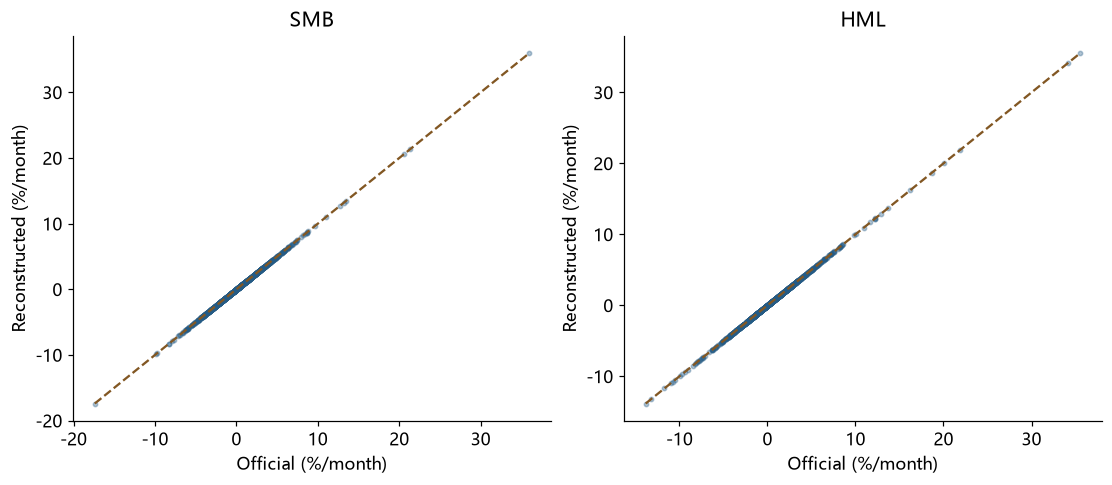

In [4]:
fig, axes = plt.subplots(1,2,figsize=(10,4.3),layout='constrained')
for ax,c in zip(axes,['SMB','HML']):
    ax.scatter(official[c]*100,constructed[c]*100,s=8,alpha=.35,color='#245b85')
    lo,hi = official[c].min()*100,official[c].max()*100
    ax.plot([lo,hi],[lo,hi],color='#825723',linestyle='--')
    ax.set(title=c,xlabel='Official (%/month)',ylabel='Reconstructed (%/month)')
plt.show()

散点图中所有点都落在 45° 线上，再次说明重建结果与官方一致。

## 为什么要用 2×3 交叉排序？
SMB 的多头和空头都包含低、中、高三种 B/M；HML 的多头和空头都包含小、大两种规模。这样，SMB 比较的是"B/M 构成相同的小公司与大公司"，HML 比较的是"规模构成相同的价值股与成长股"，两个维度的干扰被尽量隔开。如果只按规模排序，小公司组里价值股更多，SMB 就会混进价值效应。

这种平衡是按特征做的，所以 SMB 和 HML 之间仍可能有一定相关。下一关把它们放进回归，检验能否缩小 25 个组合的定价误差。

## Boss 作答区

改变教学示例中一只股票的市值，观察哪些权重和组合收益发生了变化。说明这个变化是怎样传到 SMB 和 HML 的；不要只汇报最终数值。

**我的回答：**

（由你填写；本课程未预填答案。）